In [1]:
# ============================================================
# Mitumba Trader Dataset: Exploratory Data Visualization
# ============================================================
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

warnings.filterwarnings("ignore")

# Global visual theme
PALETTE = ["#2E5EAA", "#E4572E", "#17BEBB", "#FFC914", "#76B041", "#6C4F9E"]
sns.set_theme(style="whitegrid", context="notebook", palette=PALETTE)
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 10.5,
    "axes.edgecolor": "#444444",
    "grid.alpha": 0.35,
    "legend.frameon": False,
})
kes = mtick.FuncFormatter(lambda x, _: f"{x:,.0f}")

In [2]:
# ---------- Load data ----------
paths = (glob.glob("Traders_dataset_5000*.csv") + glob.glob("/content/Traders_dataset_5000*.csv")
         + glob.glob("/content/drive/MyDrive/**/Traders_dataset_5000*.csv", recursive=True))
df = pd.read_csv(paths[0])
df["source"] = np.where(df["trader_id"].str.startswith("S"), "Synthetic", "Original")
df["wtp_share_pct"] = df["wtp_monthly_kes"] / df["monthly_income_kes"] * 100

print(f"Loaded {paths[0]}")
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1] - 2} | Missing values: {int(df.isna().sum().sum())}")
df.head()

Loaded Traders_dataset_5000__2_.csv
Rows: 5,000 | Columns: 48 | Missing values: 0


,trader_id,age,gender,education_level,language_pref,dependents,is_main_breadwinner,county,market_name,role,...,prior_microinsurance,lapse_reason,insurance_awareness_score,trust_in_insurers_score,income_tier,wtp_monthly_kes,wtp_weekly_kes,wtp_per_payment_kes,source,wtp_share_pct
0,T0109,42,male,primary,swahili,3,False,Nairobi,Gikomba Market,owner,...,never,not_applicable,2,3,low,117,27,4,Original,1.462500
1,T0925,31,female,tertiary_vocational,english,0,False,Nairobi,Toi Market,owner,...,never,not_applicable,4,3,low,255,59,59,Original,3.187500
2,T0366,22,female,tertiary_vocational,english,2,True,Nairobi,Toi Market,owner,...,never,not_applicable,3,2,low,231,53,54,Original,2.717647
3,T0322,18,male,tertiary_vocational,swahili,0,True,Nairobi,Toi Market,owner,...,never,not_applicable,3,3,low,188,43,43,Original,2.088889
4,T0069,36,female,secondary,sheng,1,False,Mombasa,Kongowea Market,owner,...,lapsed,claim_rejected_unclear_terms,5,3,low,187,43,43,Original,2.077778


In [3]:
# ---------- Headline numbers ----------
summary = pd.DataFrame({
    "Metric": ["Traders", "Median monthly income (KES)", "Median monthly WTP (KES)",
               "Median WTP as % of income", "Have used microinsurance before", "Own a smartphone", "Use M-Pesa"],
    "Value": [f"{len(df):,}",
              f"{df.monthly_income_kes.median():,.0f}",
              f"{df.wtp_monthly_kes.median():,.0f}",
              f"{df.wtp_share_pct.median():.2f}%",
              f"{(df.prior_microinsurance != 'never').mean():.1%}",
              f"{df.smartphone_owner.mean():.1%}",
              f"{df.uses_mpesa.mean():.1%}"],
})
summary

,Metric,Value
0,Traders,"5,000"
1,Median monthly income (KES),"59,000"
2,Median monthly WTP (KES),868
3,Median WTP as % of income,1.41%
4,Have used microinsurance before,24.7%
5,Own a smartphone,95.1%
6,Use M-Pesa,97.7%


In [4]:
# ---------- Helper functions ----------
def label_bars(ax, fmt="{:,.0f}", horizontal=False, pad=3):
    for p in ax.patches:
        v = p.get_width() if horizontal else p.get_height()
        if v == 0:
            continue
        if horizontal:
            ax.annotate(fmt.format(v), (p.get_width(), p.get_y() + p.get_height() / 2),
                        xytext=(pad, 0), textcoords="offset points", va="center", fontsize=9)
        else:
            ax.annotate(fmt.format(v), (p.get_x() + p.get_width() / 2, p.get_height()),
                        xytext=(0, pad), textcoords="offset points", ha="center", fontsize=9)

def pretty(s):
    return s.replace("_", " ").title()

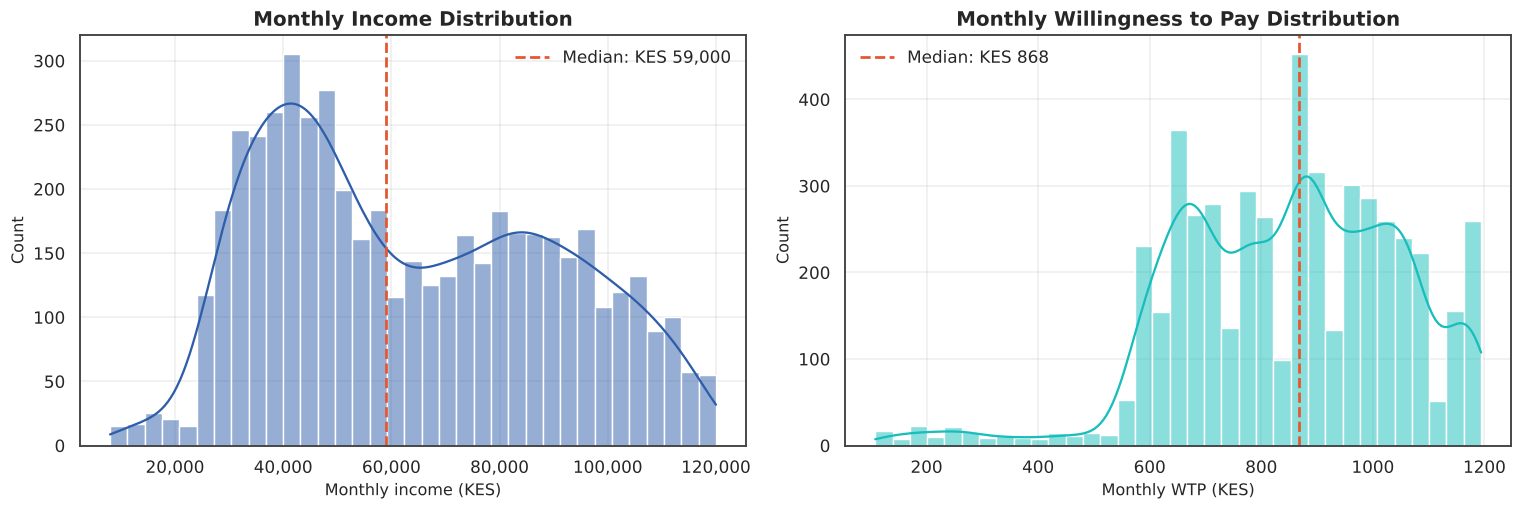

In [5]:
# ---------- 1. Income and willingness to pay: distributions ----------
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

sns.histplot(df.monthly_income_kes, bins=35, kde=True, color=PALETTE[0], ax=axes[0])
axes[0].axvline(df.monthly_income_kes.median(), color=PALETTE[1], ls="--", lw=1.8,
                label=f"Median: KES {df.monthly_income_kes.median():,.0f}")
axes[0].set_title("Monthly Income Distribution")
axes[0].set_xlabel("Monthly income (KES)")
axes[0].xaxis.set_major_formatter(kes)
axes[0].legend()

sns.histplot(df.wtp_monthly_kes, bins=35, kde=True, color=PALETTE[2], ax=axes[1])
axes[1].axvline(df.wtp_monthly_kes.median(), color=PALETTE[1], ls="--", lw=1.8,
                label=f"Median: KES {df.wtp_monthly_kes.median():,.0f}")
axes[1].set_title("Monthly Willingness to Pay Distribution")
axes[1].set_xlabel("Monthly WTP (KES)")
axes[1].legend()

plt.tight_layout()
plt.show()

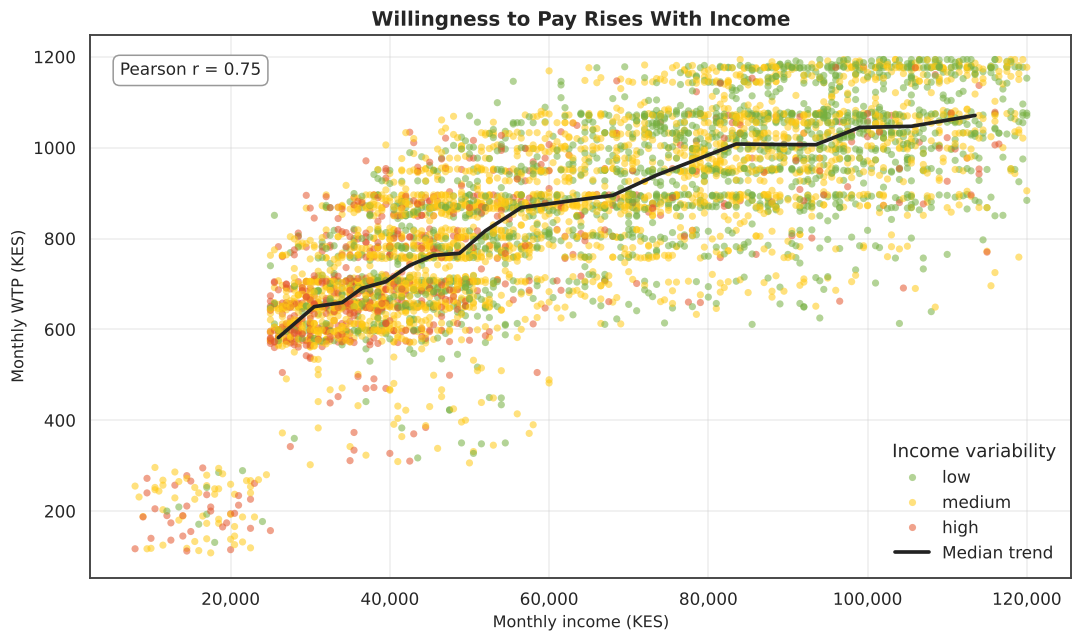

In [6]:
# ---------- 2. Income vs WTP with trend line ----------
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=df, x="monthly_income_kes", y="wtp_monthly_kes", hue="income_variability",
                hue_order=["low", "medium", "high"], palette=[PALETTE[4], PALETTE[3], PALETTE[1]],
                alpha=0.55, s=22, edgecolor="none", ax=ax)
# Trend line: median WTP within income bins
bins = pd.qcut(df.monthly_income_kes, 20, duplicates="drop")
trend = df.groupby(bins, observed=True).agg(x=("monthly_income_kes", "median"), y=("wtp_monthly_kes", "median"))
ax.plot(trend.x, trend.y, color="#222222", lw=2.4, label="Median trend")
r = df.monthly_income_kes.corr(df.wtp_monthly_kes)
ax.text(0.03, 0.95, f"Pearson r = {r:.2f}", transform=ax.transAxes, fontsize=11, va="top",
        bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="#999999"))
ax.set_title("Willingness to Pay Rises With Income")
ax.set_xlabel("Monthly income (KES)")
ax.set_ylabel("Monthly WTP (KES)")
ax.xaxis.set_major_formatter(kes)
ax.legend(title="Income variability")
plt.tight_layout()
plt.show()

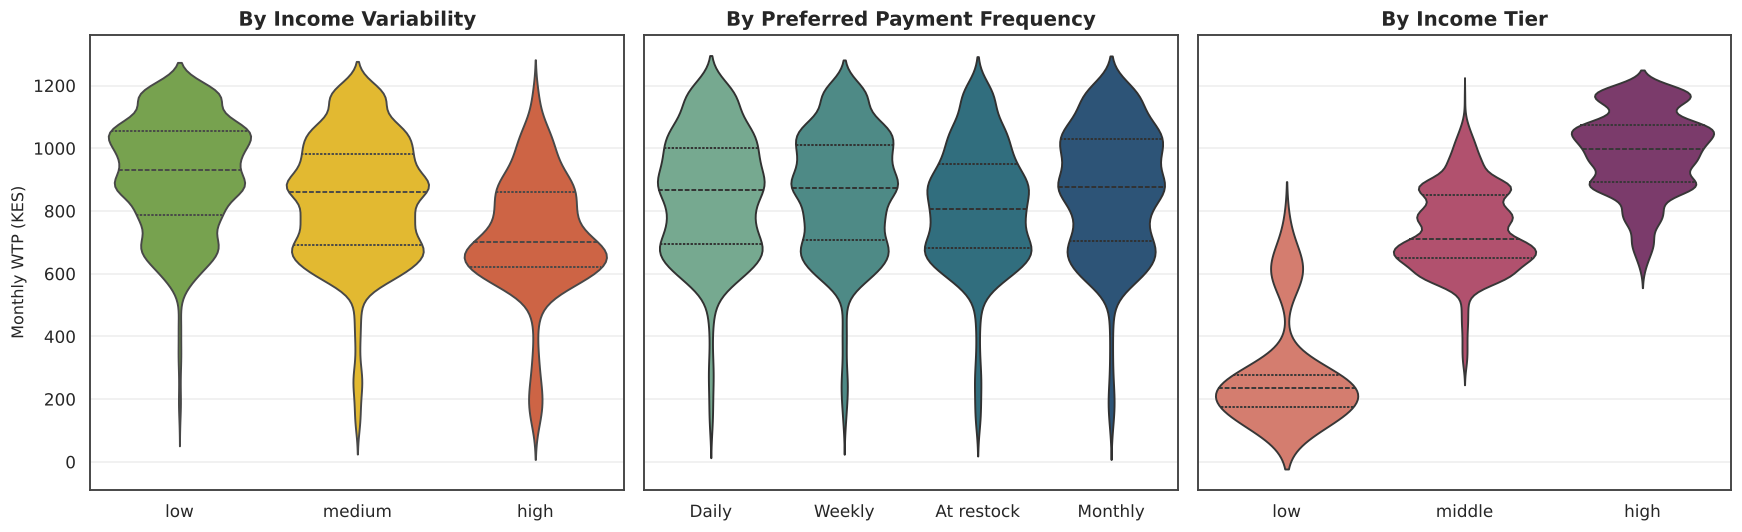

In [7]:
# ---------- 3. WTP by key segments ----------
order_var = ["low", "medium", "high"]
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)

sns.violinplot(data=df, x="income_variability", y="wtp_monthly_kes", order=order_var,
               inner="quartile", palette=[PALETTE[4], PALETTE[3], PALETTE[1]], ax=axes[0])
axes[0].set_title("By Income Variability")

sns.violinplot(data=df, x="preferred_premium_frequency", y="wtp_monthly_kes",
               order=["daily", "weekly", "pay_at_restock", "monthly"], inner="quartile",
               palette="crest", ax=axes[1])
axes[1].set_title("By Preferred Payment Frequency")
axes[1].set_xticklabels(["Daily", "Weekly", "At restock", "Monthly"])

sns.violinplot(data=df, x="income_tier", y="wtp_monthly_kes", order=["low", "middle", "high"],
               inner="quartile", palette="flare", ax=axes[2])
axes[2].set_title("By Income Tier")

axes[0].set_ylabel("Monthly WTP (KES)")
for a in axes:
    a.set_xlabel("")
plt.tight_layout()
plt.show()

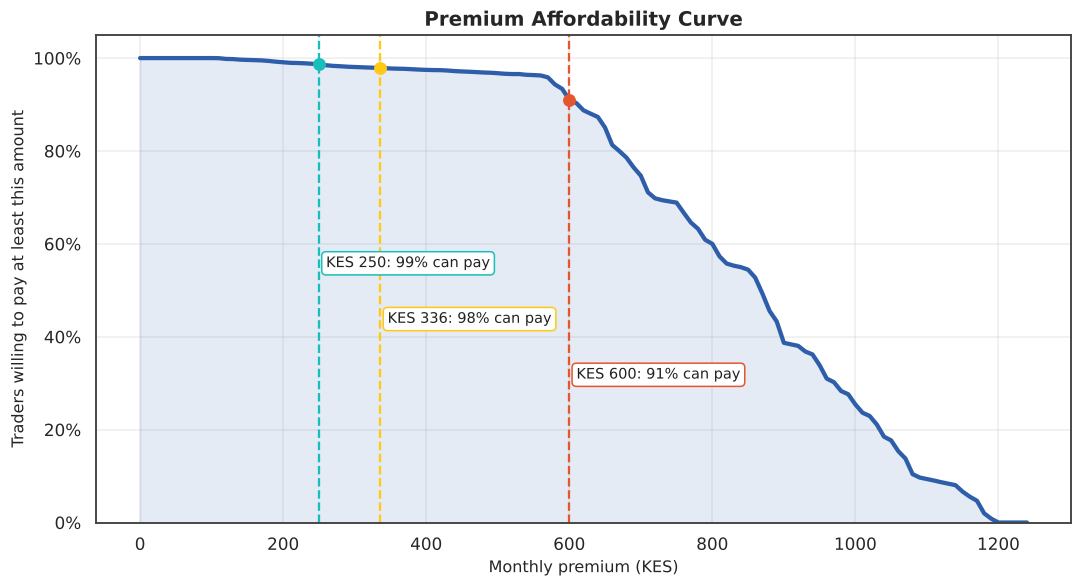

In [8]:
# ---------- 4. Affordability curve: share of traders who can pay at least X ----------
grid = np.arange(0, 1250, 10)
share = [(df.wtp_monthly_kes >= g).mean() * 100 for g in grid]

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(grid, share, color=PALETTE[0], lw=2.8)
ax.fill_between(grid, share, alpha=0.12, color=PALETTE[0])
for k, (price, name, c) in enumerate([(250, "KES 250", PALETTE[2]), (336, "KES 336", PALETTE[3]), (600, "KES 600", PALETTE[1])]):
    s = (df.wtp_monthly_kes >= price).mean() * 100
    ax.axvline(price, color=c, ls="--", lw=1.5)
    ax.scatter([price], [s], color=c, zorder=5, s=55)
    ax.text(price + 10, 55 - k * 12, f"{name}: {s:.0f}% can pay", fontsize=9.5, color="#222222",
            bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=c))
ax.set_title("Premium Affordability Curve")
ax.set_xlabel("Monthly premium (KES)")
ax.set_ylabel("Traders willing to pay at least this amount")
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylim(0, 105)
plt.tight_layout()
plt.show()

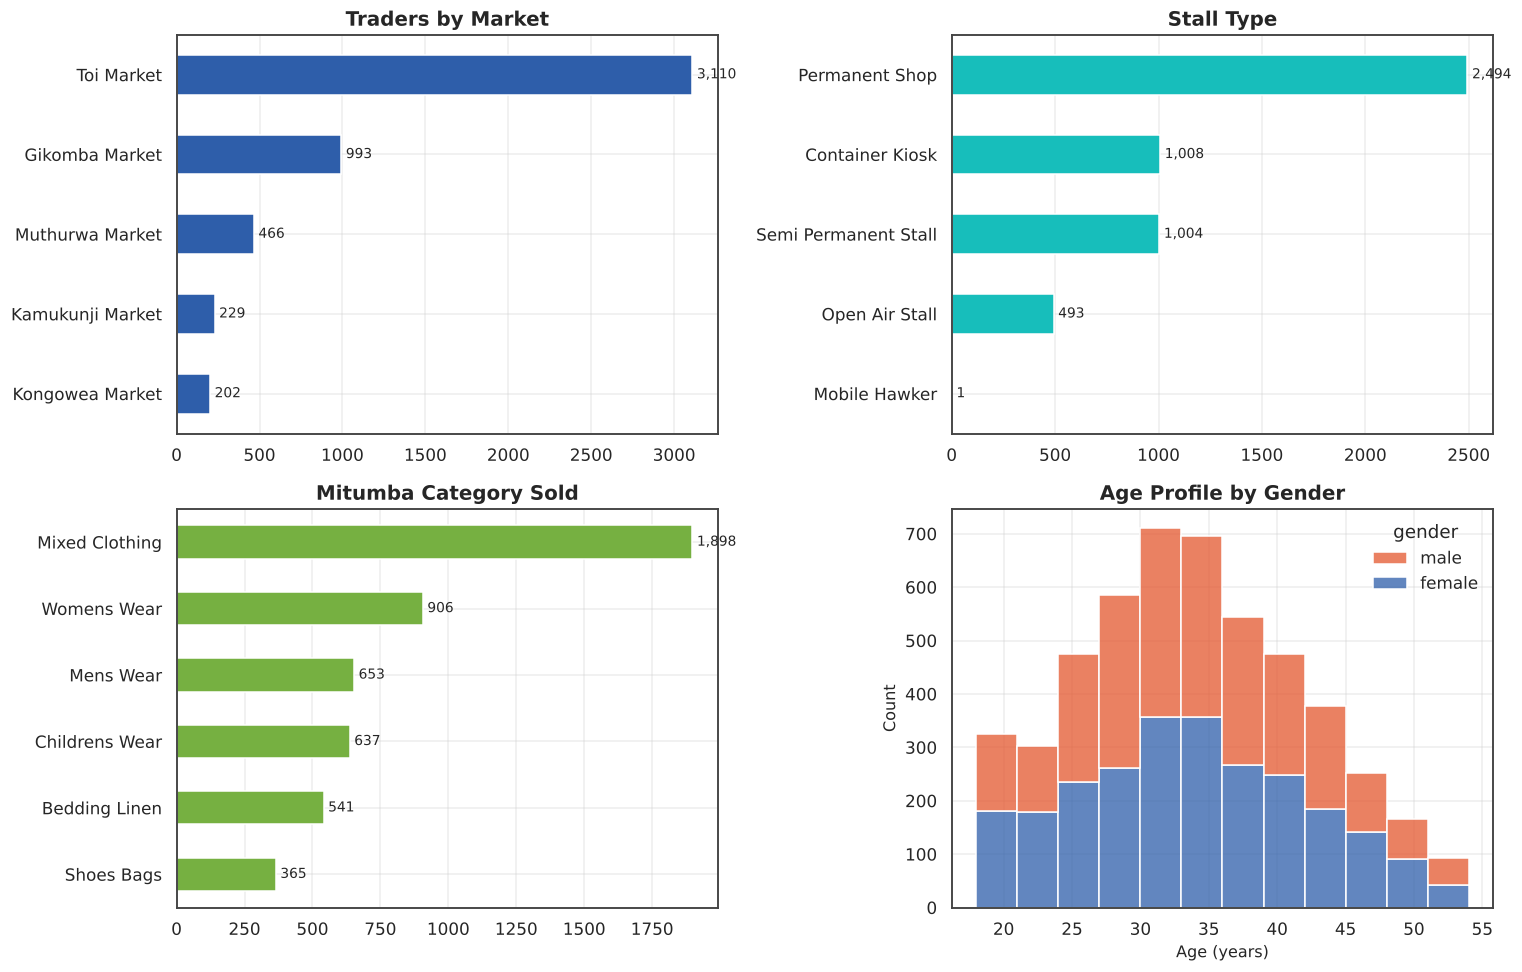

In [9]:
# ---------- 5. Who the traders are ----------
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

mk = df.market_name.value_counts().sort_values()
mk.plot.barh(ax=axes[0, 0], color=PALETTE[0])
label_bars(axes[0, 0], horizontal=True)
axes[0, 0].set_title("Traders by Market")
axes[0, 0].set_ylabel("")

st = df.stall_type.value_counts().sort_values()
st.index = [pretty(i) for i in st.index]
st.plot.barh(ax=axes[0, 1], color=PALETTE[2])
label_bars(axes[0, 1], horizontal=True)
axes[0, 1].set_title("Stall Type")

cat = df.mitumba_category.value_counts().sort_values()
cat.index = [pretty(i) for i in cat.index]
cat.plot.barh(ax=axes[1, 0], color=PALETTE[4])
label_bars(axes[1, 0], horizontal=True)
axes[1, 0].set_title("Mitumba Category Sold")

sns.histplot(data=df, x="age", hue="gender", multiple="stack", bins=range(18, 56, 3),
             palette=[PALETTE[1], PALETTE[0]], ax=axes[1, 1])
axes[1, 1].set_title("Age Profile by Gender")
axes[1, 1].set_xlabel("Age (years)")

plt.tight_layout()
plt.show()

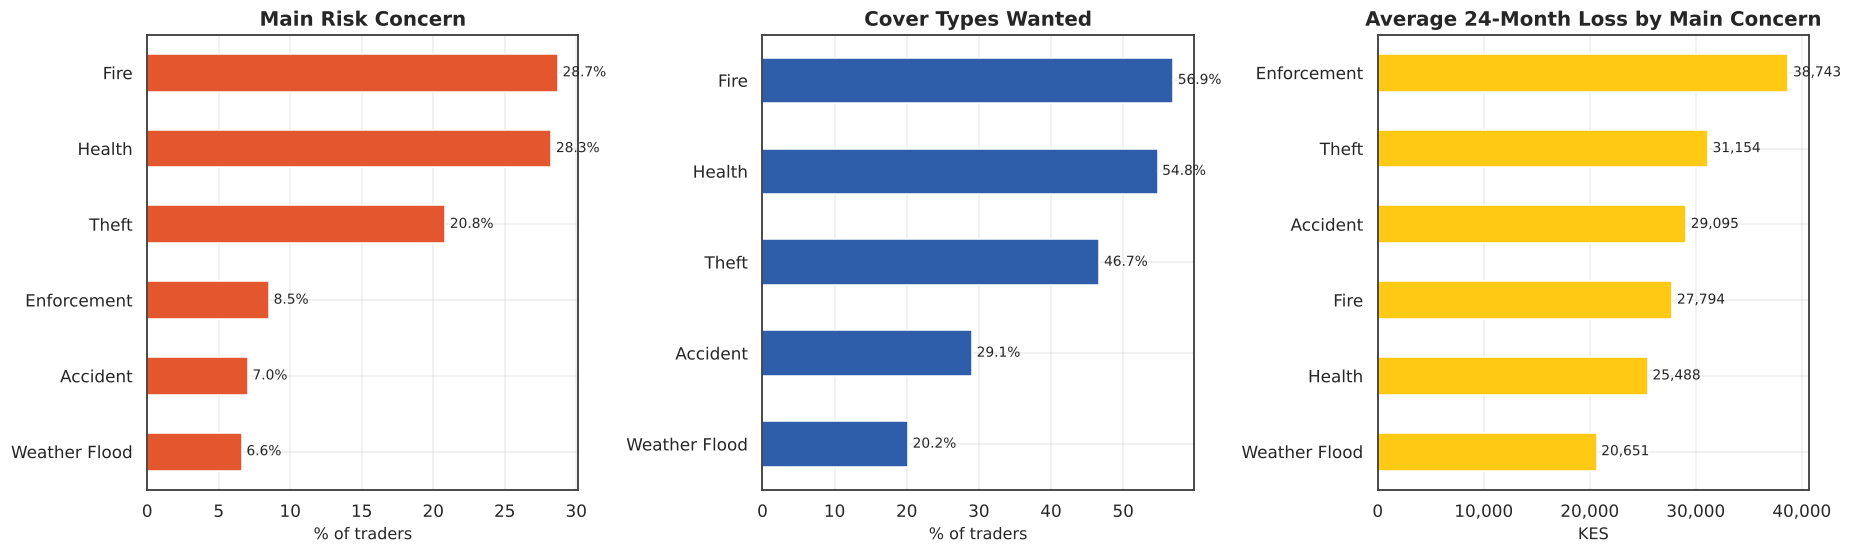

In [10]:
# ---------- 6. Risks, coverage demand and losses ----------
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))

risk = df.primary_risk_concern.value_counts(normalize=True).sort_values() * 100
risk.index = [pretty(i) for i in risk.index]
risk.plot.barh(ax=axes[0], color=PALETTE[1])
label_bars(axes[0], fmt="{:.1f}%", horizontal=True)
axes[0].set_title("Main Risk Concern")
axes[0].set_xlabel("% of traders")

cover = df[[c for c in df.columns if c.startswith("wants_cover_")]].mean().sort_values() * 100
cover.index = [pretty(i.replace("wants_cover_", "")) for i in cover.index]
cover.plot.barh(ax=axes[1], color=PALETTE[0])
label_bars(axes[1], fmt="{:.1f}%", horizontal=True)
axes[1].set_title("Cover Types Wanted")
axes[1].set_xlabel("% of traders")

loss = df.groupby("primary_risk_concern").total_loss_24m_kes.mean().sort_values()
loss.index = [pretty(i) for i in loss.index]
loss.plot.barh(ax=axes[2], color=PALETTE[3])
label_bars(axes[2], horizontal=True)
axes[2].set_title("Average 24-Month Loss by Main Concern")
axes[2].set_xlabel("KES")
axes[2].xaxis.set_major_formatter(kes)

plt.tight_layout()
plt.show()

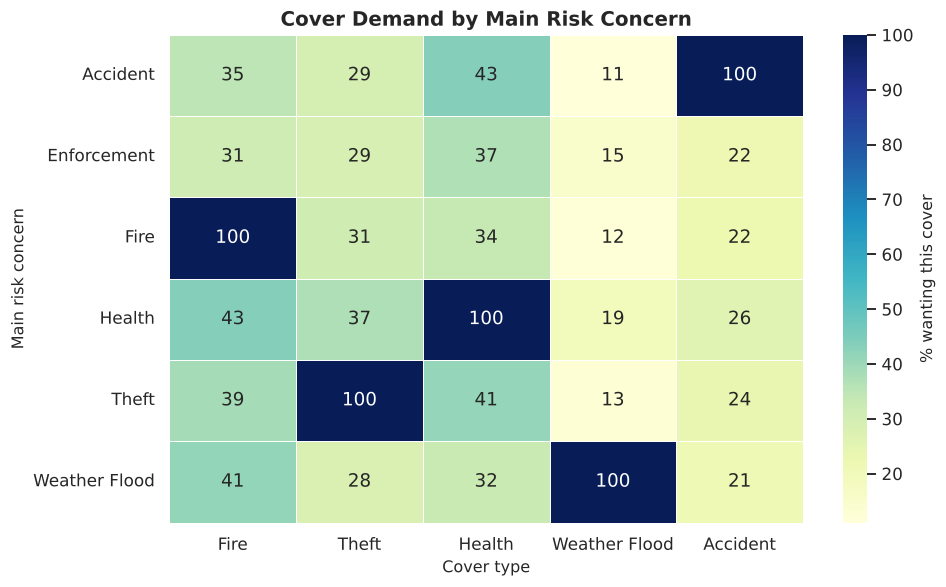

In [11]:
# ---------- 7. Main concern vs cover wanted (heatmap) ----------
cover_cols = [c for c in df.columns if c.startswith("wants_cover_")]
heat = df.groupby("primary_risk_concern")[cover_cols].mean() * 100
heat.index = [pretty(i) for i in heat.index]
heat.columns = [pretty(c.replace("wants_cover_", "")) for c in heat.columns]

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.heatmap(heat, annot=True, fmt=".0f", cmap="YlGnBu", linewidths=0.6, linecolor="white",
            cbar_kws={"label": "% wanting this cover"}, ax=ax)
ax.set_title("Cover Demand by Main Risk Concern")
ax.set_xlabel("Cover type")
ax.set_ylabel("Main risk concern")
plt.tight_layout()
plt.show()

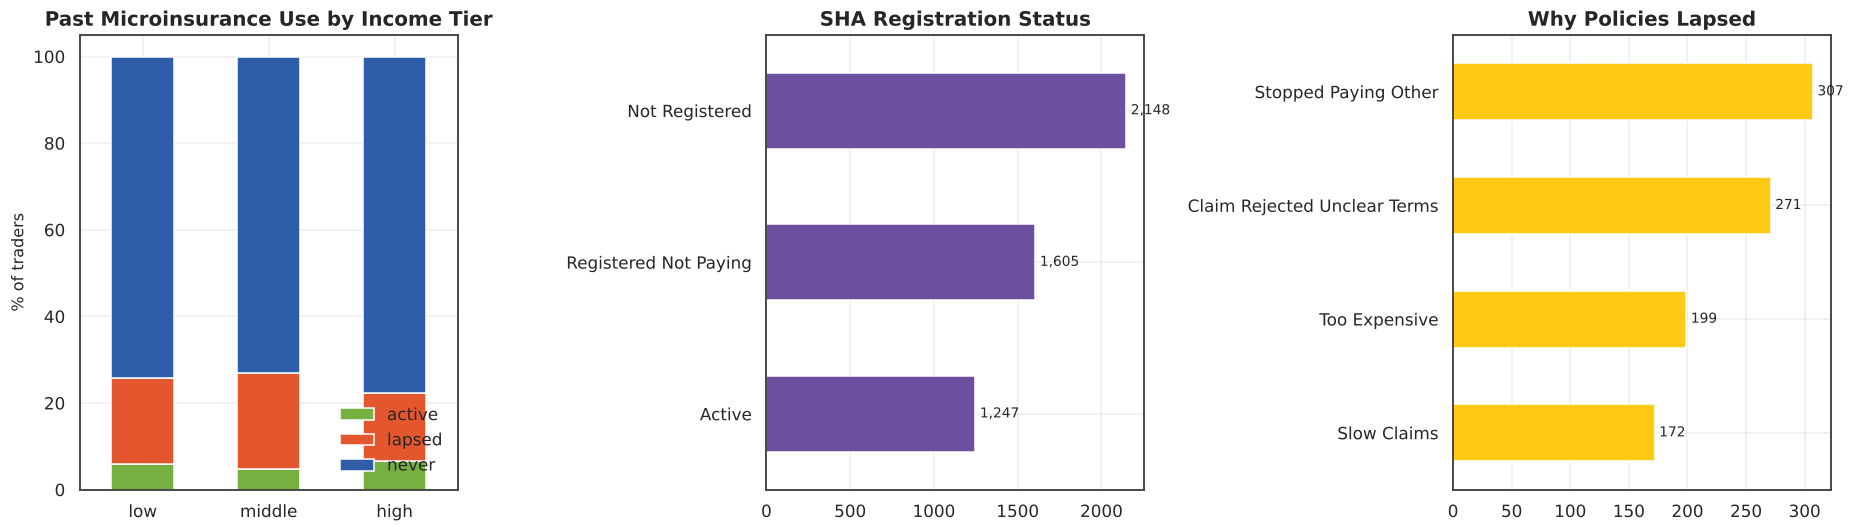

In [12]:
# ---------- 8. Insurance experience and trust ----------
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

ct = pd.crosstab(df.income_tier, df.prior_microinsurance, normalize="index").loc[["low", "middle", "high"]] * 100
ct.plot.bar(stacked=True, ax=axes[0], color=[PALETTE[4], PALETTE[1], PALETTE[0]], rot=0)
axes[0].set_title("Past Microinsurance Use by Income Tier")
axes[0].set_ylabel("% of traders")
axes[0].set_xlabel("")
axes[0].legend(title="", loc="lower right")

sha = df.sha_status.value_counts().sort_values()
sha.index = [pretty(i) for i in sha.index]
sha.plot.barh(ax=axes[1], color=PALETTE[5])
label_bars(axes[1], horizontal=True)
axes[1].set_title("SHA Registration Status")

lapsed = df[df.prior_microinsurance == "lapsed"].lapse_reason.value_counts().sort_values()
lapsed.index = [pretty(i) for i in lapsed.index]
lapsed.plot.barh(ax=axes[2], color=PALETTE[3])
label_bars(axes[2], horizontal=True)
axes[2].set_title("Why Policies Lapsed")

plt.tight_layout()
plt.show()

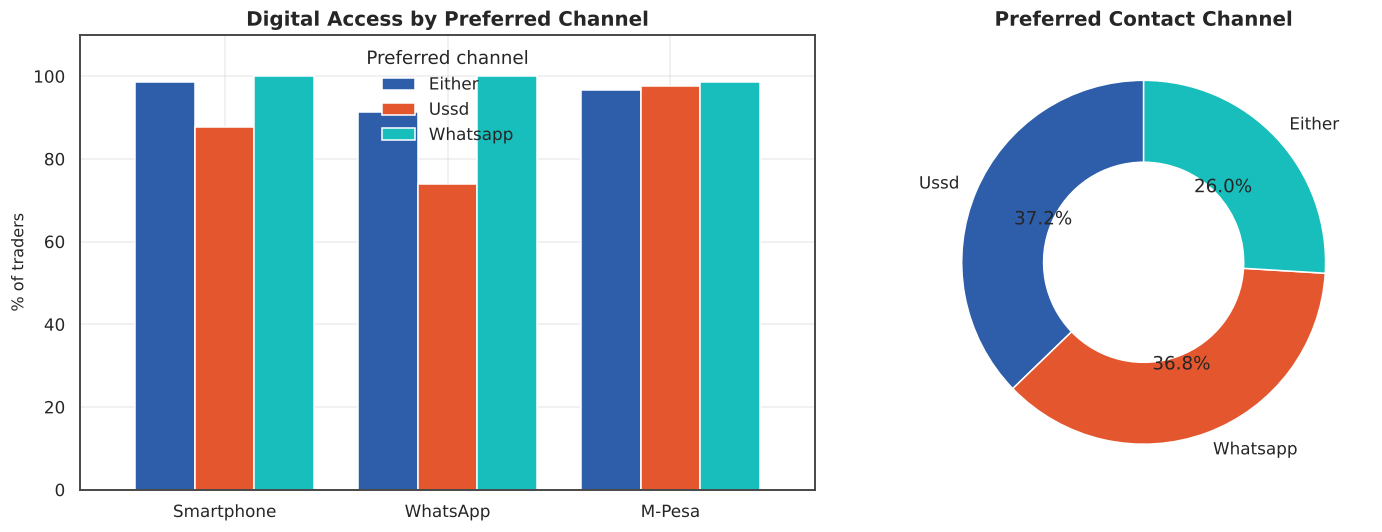

In [13]:
# ---------- 9. Digital access and preferred channel ----------
digital = df.groupby("preferred_channel")[["smartphone_owner", "whatsapp_user", "uses_mpesa"]].mean() * 100
digital.columns = ["Smartphone", "WhatsApp", "M-Pesa"]
digital.index = [pretty(i) for i in digital.index]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
digital.T.plot.bar(ax=axes[0], color=[PALETTE[0], PALETTE[1], PALETTE[2]], rot=0, width=0.8)
axes[0].set_title("Digital Access by Preferred Channel")
axes[0].set_ylabel("% of traders")
axes[0].set_xlabel("")
axes[0].legend(title="Preferred channel")
axes[0].set_ylim(0, 110)

ch = df.preferred_channel.value_counts()
axes[1].pie(ch.values, labels=[pretty(i) for i in ch.index], autopct="%1.1f%%", startangle=90,
            colors=PALETTE[:3], wedgeprops=dict(width=0.45, edgecolor="white"))
axes[1].set_title("Preferred Contact Channel")

plt.tight_layout()
plt.show()

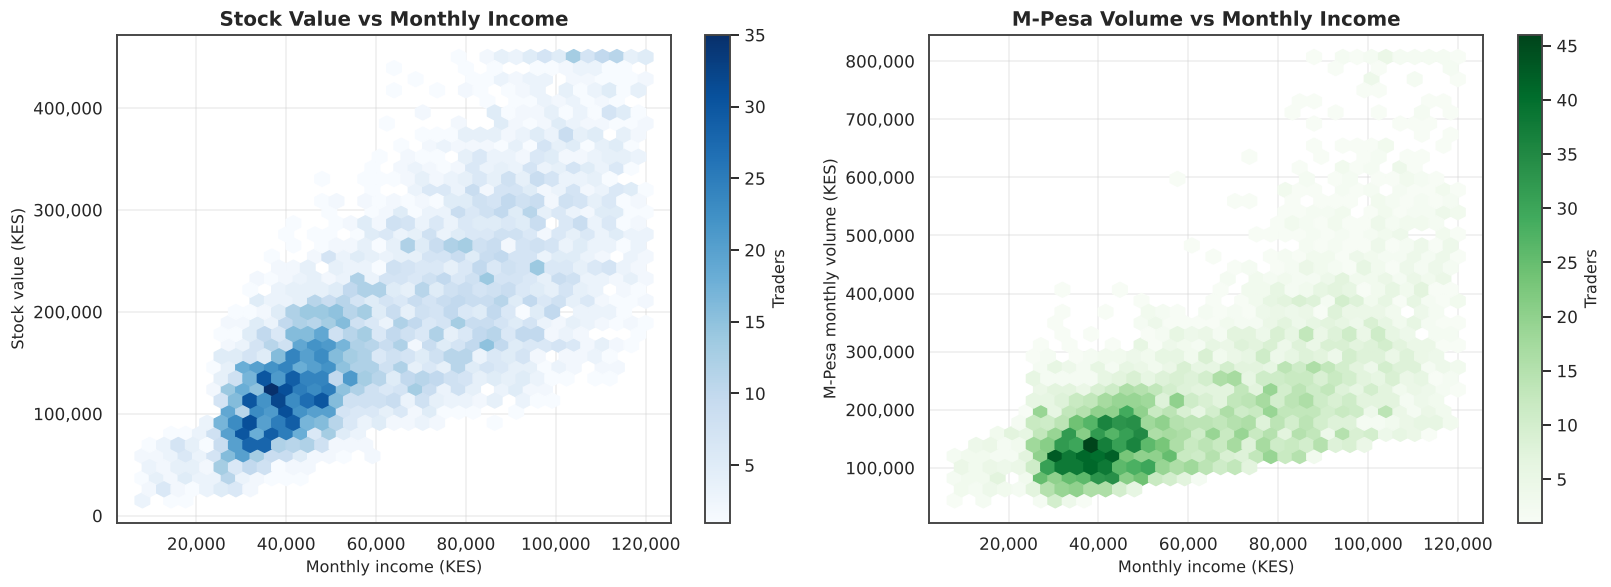

In [14]:
# ---------- 10. Stock, M-Pesa volume and income ----------
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

hb = axes[0].hexbin(df.monthly_income_kes, df.stock_value_kes, gridsize=35, cmap="Blues", mincnt=1)
axes[0].set_title("Stock Value vs Monthly Income")
axes[0].set_xlabel("Monthly income (KES)")
axes[0].set_ylabel("Stock value (KES)")
axes[0].xaxis.set_major_formatter(kes)
axes[0].yaxis.set_major_formatter(kes)
fig.colorbar(hb, ax=axes[0], label="Traders")

hb2 = axes[1].hexbin(df.monthly_income_kes, df.mpesa_monthly_volume_kes, gridsize=35, cmap="Greens", mincnt=1)
axes[1].set_title("M-Pesa Volume vs Monthly Income")
axes[1].set_xlabel("Monthly income (KES)")
axes[1].set_ylabel("M-Pesa monthly volume (KES)")
axes[1].xaxis.set_major_formatter(kes)
axes[1].yaxis.set_major_formatter(kes)
fig.colorbar(hb2, ax=axes[1], label="Traders")

plt.tight_layout()
plt.show()

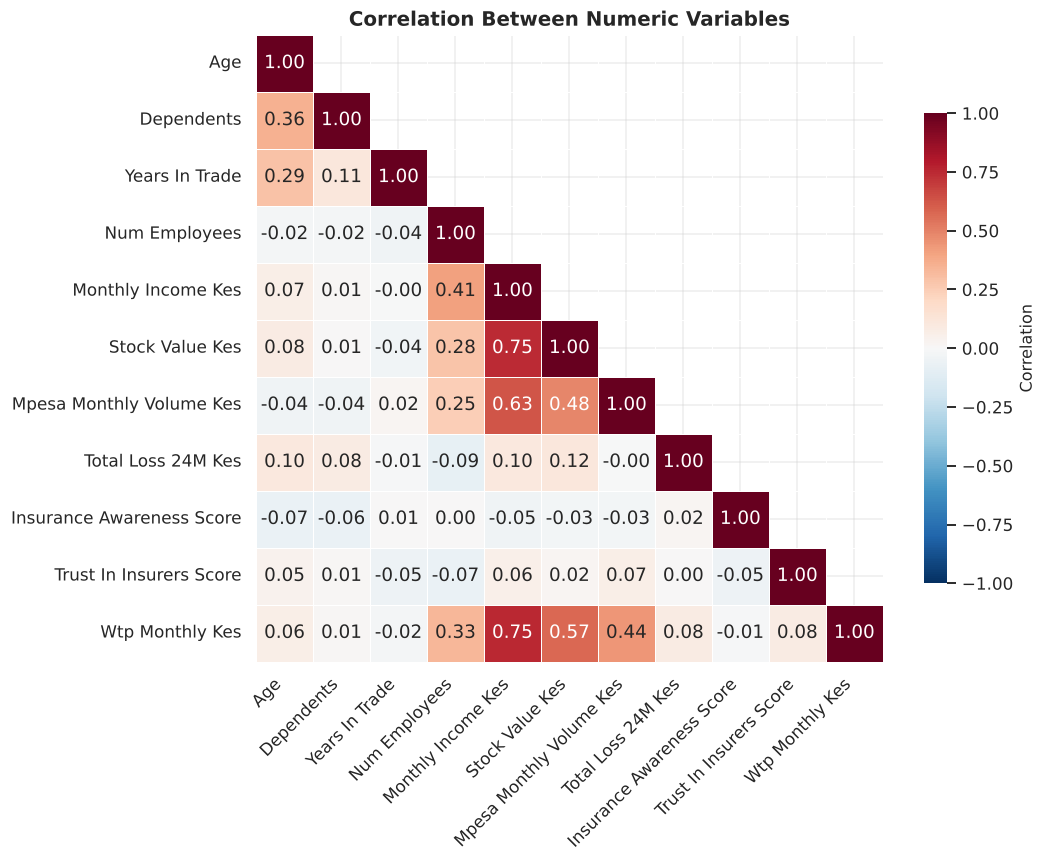

In [15]:
# ---------- 11. Correlation matrix ----------
num_cols = ["age", "dependents", "years_in_trade", "num_employees", "monthly_income_kes", "stock_value_kes",
            "mpesa_monthly_volume_kes", "total_loss_24m_kes", "insurance_awareness_score",
            "trust_in_insurers_score", "wtp_monthly_kes"]
corr = df[num_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.75, "label": "Correlation"}, ax=ax)
ax.set_xticklabels([pretty(c) for c in corr.columns], rotation=45, ha="right")
ax.set_yticklabels([pretty(c) for c in corr.index], rotation=0)
ax.set_title("Correlation Between Numeric Variables")
plt.tight_layout()
plt.show()

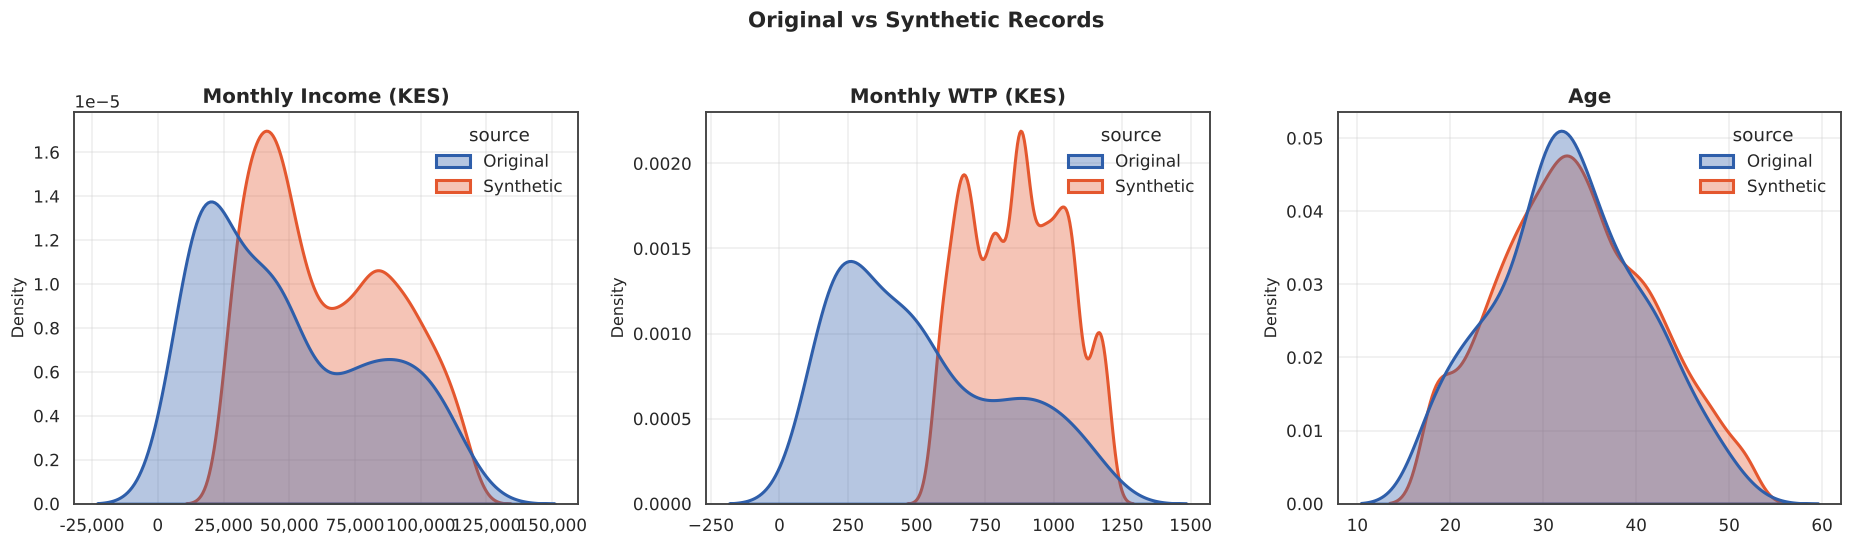

source                    Original  Synthetic
monthly_income_kes count     290.0     4710.0
                   mean    49651.7    64435.7
                   std     32116.4    25846.5
                   min      8000.0    25000.0
                   25%     20125.0    42000.0
                   50%     42250.0    60000.0
                   75%     75500.0    86000.0
                   max    120000.0   120000.0
wtp_monthly_kes    count     290.0     4710.0
                   mean      514.0      867.8
                   std       302.1      172.7
                   min       108.0      560.0
                   25%       255.2      706.0
                   50%       451.0      873.0
                   75%       757.5     1006.0
                   max      1194.0     1194.0
age                count     290.0     4710.0
                   mean       32.7       33.3
                   std         7.9        8.2
                   min        18.0       18.0
                   25%        27.2       27.0
                   50%        32.0       33.0
                   75%        38.0       39.0
                   max        52.0       52.0

In [16]:
# ---------- 12. Original vs synthetic records ----------
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, col, title in zip(axes, ["monthly_income_kes", "wtp_monthly_kes", "age"],
                          ["Monthly Income (KES)", "Monthly WTP (KES)", "Age"]):
    sns.kdeplot(data=df, x=col, hue="source", common_norm=False, fill=True, alpha=0.35, lw=2,
                palette=[PALETTE[0], PALETTE[1]], ax=ax)
    ax.set_title(title)
    ax.set_xlabel("")
axes[0].xaxis.set_major_formatter(kes)
plt.suptitle("Original vs Synthetic Records", fontsize=14, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()
df.groupby("source")[["monthly_income_kes", "wtp_monthly_kes", "age"]].describe().T.round(1)

In [17]:
# ---------- 13. Market comparison table ----------
market = (df.groupby("market_name")
            .agg(traders=("trader_id", "count"),
                 median_income=("monthly_income_kes", "median"),
                 median_wtp=("wtp_monthly_kes", "median"),
                 share_with_loss=("total_loss_24m_kes", lambda s: (s > 0).mean() * 100),
                 mpesa_users=("uses_mpesa", lambda s: s.mean() * 100))
            .round(1).sort_values("traders", ascending=False))
market.style.background_gradient(cmap="Blues", subset=["median_wtp"]).format(precision=1)

,traders,median_income,median_wtp,share_with_loss,mpesa_users
market_name,,,,,
Toi Market,3110,56000.0,861.0,57.5,98.1
Gikomba Market,993,71000.0,892.0,46.1,96.6
Muthurwa Market,466,51750.0,850.0,58.2,95.5
Kamukunji Market,229,64500.0,880.0,39.7,98.7
Kongowea Market,202,58250.0,859.0,42.1,99.5
